# Notebook 01: Tiền xử lý dữ liệu và phân tích khám phá (EDA)

**Mục tiêu của notebook:**

1. Đọc bộ dữ liệu *Online Retail II* (UCI, dataset id 502) và làm sạch theo từng bước, ghi lại số dòng còn lại sau mỗi bước.
2. Phân tích khám phá (EDA): doanh thu theo tháng, sản phẩm và quốc gia nổi bật, hành vi mua của khách hàng, giá trị đơn hàng.
3. Tạo nhãn **rời bỏ (churn)** cho từng khách hàng theo cách chia dữ liệu theo thời gian.
4. Xuất dữ liệu đã làm sạch ra `data/processed/` để các notebook sau sử dụng.

**Dữ liệu đầu ra:**

- `data/processed/transactions_clean.csv`: toàn bộ giao dịch đã làm sạch.
- `data/processed/customers.csv`: mỗi dòng là một khách hàng trong tập nghiên cứu, gồm `CustomerID` và nhãn `churn`.

## 0. Khai báo thư viện, đường dẫn và các mốc thời gian

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

RAW_FILE = Path("../data/raw/online_retail_II.csv")
PROCESSED_DIR = Path("../data/processed")
FIG_DIR = Path("../figures")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

ACTIVE_START = pd.Timestamp("2010-09-10")
REF_DATE = pd.Timestamp("2011-09-10")
PRED_END = pd.Timestamp("2011-12-10")

In [2]:
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "axes.labelsize": 10,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "axes.prop_cycle": plt.cycler(color=COLORS),
    "axes.unicode_minus": False,
})


def save_fig(fig, filename):
    fig.savefig(FIG_DIR / filename)
    print(f"Đã lưu: figures/{filename}")

## 1. Đọc dữ liệu

Bộ dữ liệu gốc trên UCI là file Excel gồm 2 sheet: `Year 2009-2010` (525.461 dòng) và `Year 2010-2011` (541.910 dòng). Trong dự án này, dữ liệu được tải về dưới dạng **file CSV đã nối sẵn 2 sheet** (`data/raw/online_retail_II.csv`, tổng 1.067.371 dòng), nên chỉ cần đọc một file. Đọc CSV cũng nhanh hơn nhiều so với đọc Excel.

Cột `Invoice` và `StockCode` được đọc dưới dạng chuỗi (vì có ký tự chữ như `C489449`, `85123A`), cột `InvoiceDate` được chuyển sang kiểu ngày giờ.

In [3]:
df_raw = pd.read_csv(
    RAW_FILE,
    dtype={"Invoice": str, "StockCode": str},
    parse_dates=["InvoiceDate"],
)
print(f"Kích thước dữ liệu gốc: {df_raw.shape[0]:,} dòng x {df_raw.shape[1]} cột")
print(f"Khoảng thời gian: {df_raw['InvoiceDate'].min()} đến {df_raw['InvoiceDate'].max()}")
df_raw.head()

Kích thước dữ liệu gốc: 1,067,371 dòng x 8 cột
Khoảng thời gian: 2009-12-01 07:45:00 đến 2011-12-09 12:50:00


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


In [4]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [5]:
missing = df_raw.isna().sum().to_frame("Số giá trị thiếu")
missing["Tỷ lệ (%)"] = missing["Số giá trị thiếu"] / len(df_raw) * 100
missing

,Số giá trị thiếu,Tỷ lệ (%)
Invoice,0,0.00
StockCode,0,0.00
Description,4382,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,243007,22.77
Country,0,0.00


**Nhận xét:** Cột `Customer ID` thiếu khoảng 23% số dòng. Những dòng này không gắn được với khách hàng cụ thể nên không dùng được cho phân khúc khách hàng và dự đoán rời bỏ. Cột `Description` thiếu một ít, chủ yếu ở các dòng điều chỉnh kho; các dòng này sẽ bị loại ở những bước làm sạch phía sau.

## 2. Làm sạch dữ liệu

Các bước làm sạch được thực hiện lần lượt, sau mỗi bước in ra số dòng còn lại để đưa vào báo cáo. Đây là bước **làm sạch** và **tích hợp** trong quy trình KDD (C1). Mỗi bước ứng với một nhóm vấn đề chất lượng dữ liệu trong chương 2 (C2, tiền xử lý):

| Bước | Vấn đề dữ liệu (C2) | Cách xử lý |
|---|---|---|
| 1 | Tích hợp dữ liệu, bản ghi dư thừa (trùng lặp) | Bỏ dòng trùng sau khi nối hai sheet |
| 2 | Dữ liệu thiếu | Bỏ qua bản ghi (*ignore the tuple*) thiếu `Customer ID` |
| 3a, 3b | Dữ liệu không nhất quán | Đơn hủy mâu thuẫn với đơn mua gốc: ghép và loại cả hai |
| 4 | Dữ liệu nhiễu | Bỏ `Quantity` ≤ 0 hoặc `Price` ≤ 0 |
| 5 | Dữ liệu nhiễu | Bỏ các mã không phải sản phẩm (phí ship, điều chỉnh...) |
| 6 | Dữ liệu không nhất quán | Một mã sản phẩm có nhiều cách ghi tên: thống nhất về một tên |
| 7 | Xây dựng thuộc tính | Tạo thuộc tính mới `TotalPrice` |

In [6]:
cleaning_log = [{"Bước": "0. Dữ liệu gốc", "Số dòng còn lại": len(df_raw)}]


def log_step(step_name, data):
    cleaning_log.append({"Bước": step_name, "Số dòng còn lại": len(data)})
    print(f"{step_name}: còn {len(data):,} dòng")

### Bước 1: Bỏ dòng trùng lặp (C2, tích hợp dữ liệu và dư thừa)

Hai sheet của file gốc **chồng lấn nhau** trong giai đoạn 01/12/2010 đến 09/12/2010 (sheet thứ nhất kết thúc ngày 09/12/2010, sheet thứ hai bắt đầu từ 01/12/2010), nên khi **tích hợp** hai nguồn dữ liệu thành một bảng, một phần dữ liệu bị lặp lại. Ngoài ra còn có các dòng bị ghi trùng trong từng sheet. Các bản ghi trùng là dữ liệu **dư thừa**, làm thổi phồng số lượng và doanh thu, nên được loại bỏ.

In [7]:
is_dup = df_raw.duplicated(keep="first")
in_overlap = (df_raw["InvoiceDate"] >= "2010-12-01") & (df_raw["InvoiceDate"] < "2010-12-10")
print(f"Số dòng trùng lặp: {is_dup.sum():,}")
print(f"  trong đó nằm ở giai đoạn chồng lấn 01-09/12/2010: {(is_dup & in_overlap).sum():,}")

df = df_raw.drop_duplicates().copy()
log_step("1. Bỏ dòng trùng lặp", df)

Số dòng trùng lặp: 34,335
  trong đó nằm ở giai đoạn chồng lấn 01-09/12/2010: 22,844


1. Bỏ dòng trùng lặp: còn 1,033,036 dòng


### Bước 2: Bỏ dòng thiếu mã khách hàng (C2, dữ liệu thiếu)

Trong C2 có nhiều cách xử lý dữ liệu thiếu: bỏ qua bản ghi, điền tay, điền bằng hằng số, giá trị trung bình hoặc giá trị có khả năng nhất. Ở đây `Customer ID` là khóa để gắn giao dịch với khách hàng, không thể suy ra hay điền bằng giá trị nào khác, nên chọn cách **bỏ qua bản ghi** (*ignore the tuple*).

Đổi tên cột `Customer ID` thành `CustomerID` cho tiện sử dụng và ép về kiểu số nguyên (vì CSV lưu dưới dạng số thực, ví dụ `13085.0`).

In [8]:
df = df.rename(columns={"Customer ID": "CustomerID"})
df = df.dropna(subset=["CustomerID"])
df["CustomerID"] = df["CustomerID"].astype(int)
log_step("2. Bỏ dòng thiếu CustomerID", df)

2. Bỏ dòng thiếu CustomerID: còn 797,885 dòng


### Bước 3: Bỏ hóa đơn bị hủy và hóa đơn điều chỉnh (C2, dữ liệu không nhất quán)

Một đơn mua và đơn hủy tương ứng của nó **mâu thuẫn** nhau: dữ liệu ghi nhận một giao dịch đã xảy ra nhưng thực tế giao dịch đó bị hủy. Đây là dạng **dữ liệu không nhất quán** trong C2, cần được phát hiện và sửa.

- Mã hóa đơn bắt đầu bằng `C` là hóa đơn bị hủy (số lượng âm).
- Mã hóa đơn bắt đầu bằng `A` là bút toán điều chỉnh nợ xấu (*adjust bad debt*), không phải giao dịch mua hàng.

**Bước 3a: Bỏ cả đơn mua gốc đã bị hủy.** Mỗi dòng hủy thường ứng với một dòng mua trước đó của **cùng khách, cùng sản phẩm, cùng số lượng**. Nếu chỉ bỏ dòng hủy, dòng mua gốc vẫn còn và làm doanh thu của khách bị thổi phồng. Ví dụ điển hình: một khách đặt 80.995 sản phẩm "PAPER CRAFT , LITTLE BIRDIE" (£168.470) rồi hủy ngay trong ngày; nếu giữ lại đơn mua gốc, sản phẩm này sẽ lọt top 3 doanh thu và khách đó trở thành khách "chi tiêu nhiều nhất" một cách sai lệch.

Cách làm: với mỗi dòng hủy, tìm dòng mua **gần nhất trước đó** khớp cả 3 thông tin trên (dùng `pd.merge_asof`), rồi loại dòng mua đó. Những dòng hủy không tìm được đơn gốc (ví dụ đơn gốc nằm trước thời điểm bắt đầu dữ liệu, hoặc chỉ hủy một phần) thì chỉ loại dòng hủy.

**Chỉ ghép khi đơn hủy và đơn mua gốc nằm cùng một giai đoạn** so với ngày tham chiếu 10/09/2011 (cùng trước, hoặc cùng từ ngày này trở đi). Lý do: tại thời điểm 10/09/2011 ta chưa thể biết một đơn mua trong giai đoạn quan sát sẽ bị hủy ở giai đoạn dự đoán; nếu dùng đơn hủy đó để xóa đơn mua, dữ liệu giai đoạn quan sát (và các đặc trưng RFM tính từ nó) đã bị "nhìn trước" thông tin của tương lai, tức là rò rỉ dữ liệu (*data leakage*).

**Bước 3b:** loại toàn bộ hóa đơn `C` và `A`.

In [9]:
is_cancel = df["Invoice"].str.startswith("C")
cancels = df[is_cancel].copy()
cancels["Quantity"] = -cancels["Quantity"]
purchases = df[~is_cancel & (df["Quantity"] > 0)].reset_index().rename(columns={"index": "row_id"})

cancels["Period"] = np.where(cancels["InvoiceDate"] < REF_DATE, "observation", "prediction")
purchases["Period"] = np.where(purchases["InvoiceDate"] < REF_DATE, "observation", "prediction")


def match_cancellations(by):
    return pd.merge_asof(
        cancels.sort_values("InvoiceDate"),
        purchases.sort_values("InvoiceDate")[["InvoiceDate", "row_id"] + by],
        on="InvoiceDate",
        by=by,
        direction="backward",
    )


matched = match_cancellations(["CustomerID", "StockCode", "Quantity", "Period"])
matched_any_period = match_cancellations(["CustomerID", "StockCode", "Quantity"])
n_cross_period = matched_any_period["row_id"].notna().sum() - matched["row_id"].notna().sum()

rows_to_drop = matched["row_id"].dropna().unique()
removed = df.loc[rows_to_drop]
print(f"Số dòng hủy: {is_cancel.sum():,}, tìm được đơn mua gốc cùng giai đoạn cho {matched['row_id'].notna().sum():,} dòng")
print(f"Số dòng hủy ở giai đoạn dự đoán có đơn mua gốc ở giai đoạn quan sát (không ghép): {n_cross_period:,}")
print(f"Doanh thu của các đơn mua gốc bị loại: £{(removed['Quantity'] * removed['Price']).sum():,.0f}")
print("\nCác đơn mua gốc có giá trị lớn nhất bị loại:")
print(removed.assign(Value=removed["Quantity"] * removed["Price"])
      .nlargest(5, "Value")[["Invoice", "Description", "Quantity", "InvoiceDate", "CustomerID", "Value"]]
      .to_string(index=False))

df = df.drop(index=rows_to_drop)
log_step("3a. Bỏ đơn mua gốc đã bị hủy", df)

Số dòng hủy: 18,390, tìm được đơn mua gốc cùng giai đoạn cho 6,242 dòng
Số dòng hủy ở giai đoạn dự đoán có đơn mua gốc ở giai đoạn quan sát (không ghép): 331
Doanh thu của các đơn mua gốc bị loại: £665,854

Các đơn mua gốc có giá trị lớn nhất bị loại:
Invoice                         Description  Quantity         InvoiceDate  CustomerID      Value
 581483         PAPER CRAFT , LITTLE BIRDIE     80995 2011-12-09 09:15:00       16446 168,469.60
 541431      MEDIUM CERAMIC TOP STORAGE JAR     74215 2011-01-18 10:01:00       12346  77,183.60
 556444      PICNIC BASKET WICKER 60 PIECES        60 2011-06-10 15:28:00       15098  38,970.00
 530715 ROTATING SILVER ANGELS T-LIGHT HLDR      9360 2010-11-04 11:36:00       15838  15,818.40
 502263                              Manual         1 2010-03-23 15:22:00       12918  10,953.50
3a. Bỏ đơn mua gốc đã bị hủy: còn 791,852 dòng


In [10]:
print("Số dòng có Invoice bắt đầu bằng 'C':", df["Invoice"].str.startswith("C").sum())
print("Số dòng có Invoice bắt đầu bằng 'A':", df["Invoice"].str.startswith("A").sum())

df = df[~df["Invoice"].str.startswith(("C", "A"))]
log_step("3b. Bỏ hóa đơn hủy (C) và điều chỉnh (A)", df)

Số dòng có Invoice bắt đầu bằng 'C': 18390
Số dòng có Invoice bắt đầu bằng 'A': 0


3b. Bỏ hóa đơn hủy (C) và điều chỉnh (A): còn 773,462 dòng


**Nhận xét:** Các hóa đơn điều chỉnh (`A`) đều không có mã khách hàng nên đã bị loại từ bước 2; ở bước 3b chỉ còn hóa đơn hủy cần loại.

### Bước 4: Bỏ dòng có số lượng hoặc đơn giá không hợp lệ (C2, dữ liệu nhiễu)

Số lượng hoặc đơn giá ≤ 0 ở một dòng mua hàng là giá trị sai, không phản ánh giao dịch thật. Đây là **nhiễu** (lỗi ngẫu nhiên khi ghi nhận dữ liệu), nên được loại bỏ.

In [11]:
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)]
log_step("4. Bỏ Quantity <= 0 hoặc Price <= 0", df)

4. Bỏ Quantity <= 0 hoặc Price <= 0: còn 773,393 dòng


### Bước 5: Bỏ các mã không phải sản phẩm (C2, dữ liệu nhiễu)

Một số `StockCode` không phải hàng hóa thật mà là phí vận chuyển (`POST`, `DOT`), phí ngân hàng (`BANK CHARGES`), điều chỉnh thủ công (`M`, `ADJUST`), hàng mẫu, mã thử nghiệm... Mã sản phẩm thật luôn bắt đầu bằng 5 chữ số (ví dụ `85123A`, `22423`), nên chỉ giữ các dòng có `StockCode` khớp biểu thức chính quy `^\d{5}`.

In [12]:
is_product = df["StockCode"].str.match(r"^\d{5}")
print("Các mã bị loại (không phải sản phẩm) và số dòng tương ứng:")
print(df.loc[~is_product, "StockCode"].value_counts().to_string())

df = df[is_product]
log_step("5. Chỉ giữ StockCode là sản phẩm", df)

Các mã bị loại (không phải sản phẩm) và số dòng tương ứng:
StockCode
POST            1760
M                592
C2               242
ADJUST            32
BANK CHARGES      29
PADS              16
DOT               16
TEST001            9
D                  3
ADJUST2            3
SP1002             2
TEST002            1
5. Chỉ giữ StockCode là sản phẩm: còn 770,688 dòng


### Bước 6: Chuẩn hóa tên sản phẩm (C2, dữ liệu không nhất quán)

Cùng một `StockCode` đôi khi có nhiều cách ghi `Description` khác nhau (khác khoảng trắng, sửa tên trong quá trình bán). Vì notebook 04 dùng tên sản phẩm làm "item" trong luật kết hợp, ta chuẩn hóa: bỏ khoảng trắng thừa, rồi gán cho mỗi `StockCode` **tên xuất hiện nhiều nhất** của nó. Bước này không làm thay đổi số dòng.

In [13]:
df["Description"] = df["Description"].str.strip()
n_codes_multi_desc = (df.groupby("StockCode")["Description"].nunique() > 1).sum()
print(f"Số StockCode có nhiều hơn 1 tên: {n_codes_multi_desc}")

most_common_desc = df.groupby("StockCode")["Description"].agg(lambda s: s.value_counts().index[0])
df["Description"] = df["StockCode"].map(most_common_desc)
print(f"Sau chuẩn hóa: {df['StockCode'].nunique():,} mã sản phẩm, {df['Description'].nunique():,} tên sản phẩm")

Số StockCode có nhiều hơn 1 tên: 595


Sau chuẩn hóa: 4,611 mã sản phẩm, 4,574 tên sản phẩm


### Bước 7: Tạo cột thành tiền `TotalPrice = Quantity * Price` (C2, xây dựng thuộc tính)

Thuộc tính mới `TotalPrice` được xây dựng từ hai thuộc tính có sẵn. Đây là bước **xây dựng thuộc tính** (*attribute construction*) trong C2.

In [14]:
df["TotalPrice"] = df["Quantity"] * df["Price"]
df = df.sort_values("InvoiceDate").reset_index(drop=True)
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,TotalPrice
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.40
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.00
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.00
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.80
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.00


### Tổng hợp quá trình làm sạch

In [15]:
cleaning_summary = pd.DataFrame(cleaning_log)
cleaning_summary["Số dòng bị loại"] = (-cleaning_summary["Số dòng còn lại"].diff()).fillna(0).astype(int)
cleaning_summary["% còn lại so với gốc"] = cleaning_summary["Số dòng còn lại"] / len(df_raw) * 100
cleaning_summary.style.format({"Số dòng còn lại": "{:,}", "Số dòng bị loại": "{:,}", "% còn lại so với gốc": "{:.1f}%"})

,Bước,Số dòng còn lại,Số dòng bị loại,% còn lại so với gốc
0,0. Dữ liệu gốc,"1,067,371",0,100.0%
1,1. Bỏ dòng trùng lặp,"1,033,036","34,335",96.8%
2,2. Bỏ dòng thiếu CustomerID,"797,885","235,151",74.8%
3,3a. Bỏ đơn mua gốc đã bị hủy,"791,852","6,033",74.2%
4,3b. Bỏ hóa đơn hủy (C) và điều chỉnh (A),"773,462","18,390",72.5%
5,4. Bỏ Quantity <= 0 hoặc Price <= 0,"773,393",69,72.5%
6,5. Chỉ giữ StockCode là sản phẩm,"770,688","2,705",72.2%


**Nhận xét:** Từ 1.067.371 dòng ban đầu, sau làm sạch còn **770.688 dòng (72,2%)**. Bước loại nhiều nhất là bỏ dòng thiếu `CustomerID` (235.151 dòng, khoảng 22% dữ liệu); đây là mất mát bắt buộc vì bài toán xoay quanh từng khách hàng. Bỏ trùng lặp loại 34.335 dòng, trong đó 22.844 dòng nằm ở giai đoạn hai sheet chồng lấn. Việc ghép hóa đơn hủy với đơn mua gốc cùng giai đoạn loại thêm 6.033 dòng mua (khoảng £666K doanh thu "ảo"). Có 331 dòng hủy nằm ở giai đoạn dự đoán nhưng đơn mua gốc ở giai đoạn quan sát; các đơn mua này được giữ lại để không dùng thông tin tương lai, và chỉ làm thay đổi khoảng 0,04% số dòng. Các mã không phải sản phẩm (chủ yếu là `POST`, phí bưu điện) chỉ chiếm 2.705 dòng.

## 3. Phân tích khám phá dữ liệu (EDA)

### 3.1. Tổng quan dữ liệu sau làm sạch

In [16]:
overview = pd.Series({
    "Số dòng giao dịch": f"{len(df):,}",
    "Số hóa đơn": f"{df['Invoice'].nunique():,}",
    "Số khách hàng": f"{df['CustomerID'].nunique():,}",
    "Số sản phẩm": f"{df['StockCode'].nunique():,}",
    "Số quốc gia": f"{df['Country'].nunique()}",
    "Tổng doanh thu (GBP)": f"{df['TotalPrice'].sum():,.0f}",
    "Từ ngày": df["InvoiceDate"].min().strftime("%d/%m/%Y"),
    "Đến ngày": df["InvoiceDate"].max().strftime("%d/%m/%Y"),
}).to_frame("Giá trị")
overview

,Giá trị
Số dòng giao dịch,"770,688"
Số hóa đơn,"36,334"
Số khách hàng,"5,839"
Số sản phẩm,"4,611"
Số quốc gia,41
Tổng doanh thu (GBP),"16,473,874"
Từ ngày,01/12/2009
Đến ngày,09/12/2011


### 3.2. Doanh thu theo tháng

Mục đích: xem xu hướng và tính mùa vụ của doanh thu. Vùng tô xám là **giai đoạn dự đoán** (10/09/2011 đến 09/12/2011) dùng để tạo nhãn churn ở mục 4.

Đã lưu: figures/01_doanh_thu_theo_thang.png


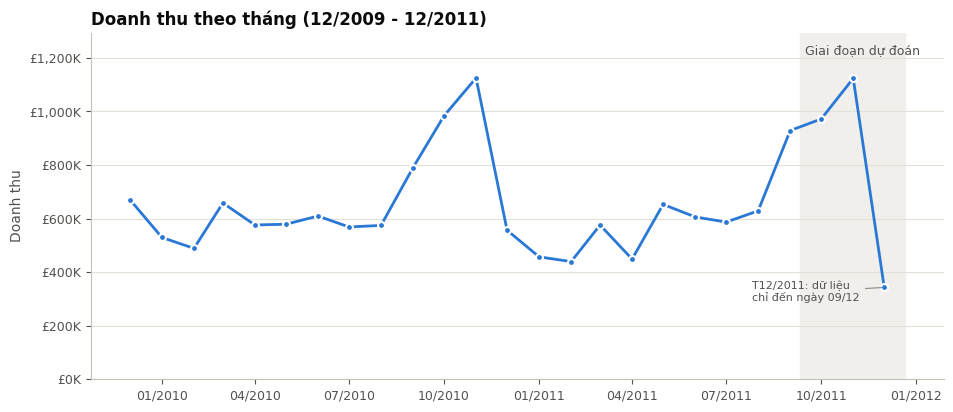

,Revenue,Customers,Invoices
InvoiceDate,,,
2011-07-01 00:00:00,"586,857",945,1314
2011-08-01 00:00:00,"628,847",933,1265
2011-09-01 00:00:00,"928,728",1255,1729
2011-10-01 00:00:00,"971,911",1356,1885
2011-11-01 00:00:00,"1,123,570",1657,2631
2011-12-01 00:00:00,"342,871",610,771


In [17]:
monthly = df.groupby(df["InvoiceDate"].dt.to_period("M")).agg(
    Revenue=("TotalPrice", "sum"),
    Customers=("CustomerID", "nunique"),
    Invoices=("Invoice", "nunique"),
)
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.axvspan(REF_DATE, monthly.index.max() + pd.Timedelta(days=20), color="#f0efec", zorder=0)
ax.plot(monthly.index, monthly["Revenue"], color=COLORS[0], marker="o", markersize=5,
        markeredgecolor="white", markeredgewidth=1.5)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"£{x / 1e3:,.0f}K"))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.set_title("Doanh thu theo tháng (12/2009 - 12/2011)")
ax.set_ylabel("Doanh thu")
ax.set_ylim(0, monthly["Revenue"].max() * 1.15)
ax.text(REF_DATE + pd.Timedelta(days=5), monthly["Revenue"].max() * 1.08, "Giai đoạn dự đoán",
        color=INK_2, fontsize=9)
last_month = monthly.index[-1]
ax.annotate("T12/2011: dữ liệu\nchỉ đến ngày 09/12", xy=(last_month, monthly["Revenue"].iloc[-1]),
            xytext=(-95, -10), textcoords="offset points", fontsize=8, color=INK_2,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
save_fig(fig, "01_doanh_thu_theo_thang.png")
plt.show()

monthly.tail(6).style.format({"Revenue": "{:,.0f}"})

**Nhận xét:** - Doanh thu có **tính mùa vụ rất rõ**: tăng mạnh từ tháng 9, đạt đỉnh vào tháng 11 (khoảng £1,1 triệu cả năm 2010 và 2011) rồi giảm sâu vào tháng 12 đến tháng 2. Điều này phù hợp với một cửa hàng quà tặng, khách sỉ nhập hàng chuẩn bị cho mùa Giáng sinh.
- Các tháng còn lại khá ổn định, khoảng £450K đến £650K mỗi tháng.
- Giai đoạn dự đoán (10/09 đến 09/12/2011) rơi đúng **mùa cao điểm**. Vì vậy một khách "không mua gì trong giai đoạn này" là tín hiệu rời bỏ khá mạnh, vì đây là thời điểm khách thường quay lại mua nhiều nhất.
- Tháng 12/2011 thấp bất thường chỉ vì dữ liệu dừng ở ngày 09/12, không phải doanh số sụt giảm.

### 3.3. Top 10 sản phẩm

Xếp hạng sản phẩm theo hai tiêu chí: tổng doanh thu và tổng số lượng bán ra.

Đã lưu: figures/01_top10_san_pham.png


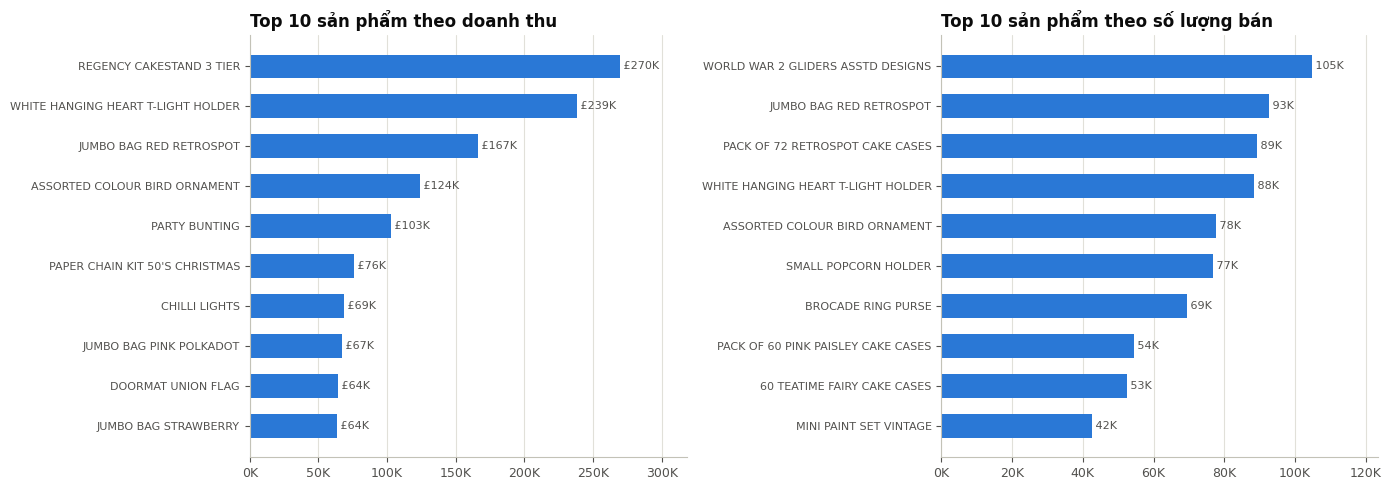

,Revenue,Quantity,Customers
Description,,,
REGENCY CAKESTAND 3 TIER,"269,681","23,430","1,299"
WHITE HANGING HEART T-LIGHT HOLDER,"238,597","88,463","1,484"
JUMBO BAG RED RETROSPOT,"166,530","92,648",975
ASSORTED COLOUR BIRD ORNAMENT,"123,681","77,784","1,007"
PARTY BUNTING,"102,677","23,321",894
PAPER CHAIN KIT 50'S CHRISTMAS,"75,606","27,995",890
CHILLI LIGHTS,"68,623","14,737",302
JUMBO BAG PINK POLKADOT,"66,963","36,887",600
DOORMAT UNION FLAG,"64,122","9,860",676


In [18]:
product_stats = df.groupby("Description").agg(
    Revenue=("TotalPrice", "sum"),
    Quantity=("Quantity", "sum"),
    Customers=("CustomerID", "nunique"),
)
top_revenue = product_stats.nlargest(10, "Revenue")
top_quantity = product_stats.nlargest(10, "Quantity")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, data, col, title, fmt in [
    (axes[0], top_revenue, "Revenue", "Top 10 sản phẩm theo doanh thu", lambda v: f"£{v / 1e3:,.0f}K"),
    (axes[1], top_quantity, "Quantity", "Top 10 sản phẩm theo số lượng bán", lambda v: f"{v / 1e3:,.0f}K"),
]:
    data = data.sort_values(col)
    ax.barh(data.index, data[col], height=0.6, color=COLORS[0])
    for y, v in enumerate(data[col]):
        ax.text(v, y, " " + fmt(v), va="center", fontsize=8, color=INK_2)
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.set_xlim(0, data[col].max() * 1.18)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x / 1e3:,.0f}K"))
    ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
save_fig(fig, "01_top10_san_pham.png")
plt.show()

top_revenue.style.format({"Revenue": "{:,.0f}", "Quantity": "{:,}", "Customers": "{:,}"})

**Nhận xét:** - Theo doanh thu, dẫn đầu là **REGENCY CAKESTAND 3 TIER** (£270K) và **WHITE HANGING HEART T-LIGHT HOLDER** (£239K), cả hai đều được hơn 1.200 khách mua.
- Theo số lượng, dẫn đầu là các mặt hàng giá rẻ bán theo lô lớn như **WORLD WAR 2 GLIDERS ASSTD DESIGNS** (105K cái), túi **JUMBO BAG RED RETROSPOT**, khuôn bánh **PACK OF 72 RETROSPOT CAKE CASES**.
- Sản phẩm chủ yếu là đồ trang trí nhà cửa, quà tặng, đồ dùng làm bánh. Số lượng mỗi lần mua lớn cho thấy nhiều khách là **người bán lại (bán sỉ)**, không phải người tiêu dùng cuối.

### 3.4. Top 10 quốc gia

Đã lưu: figures/01_top10_quoc_gia.png


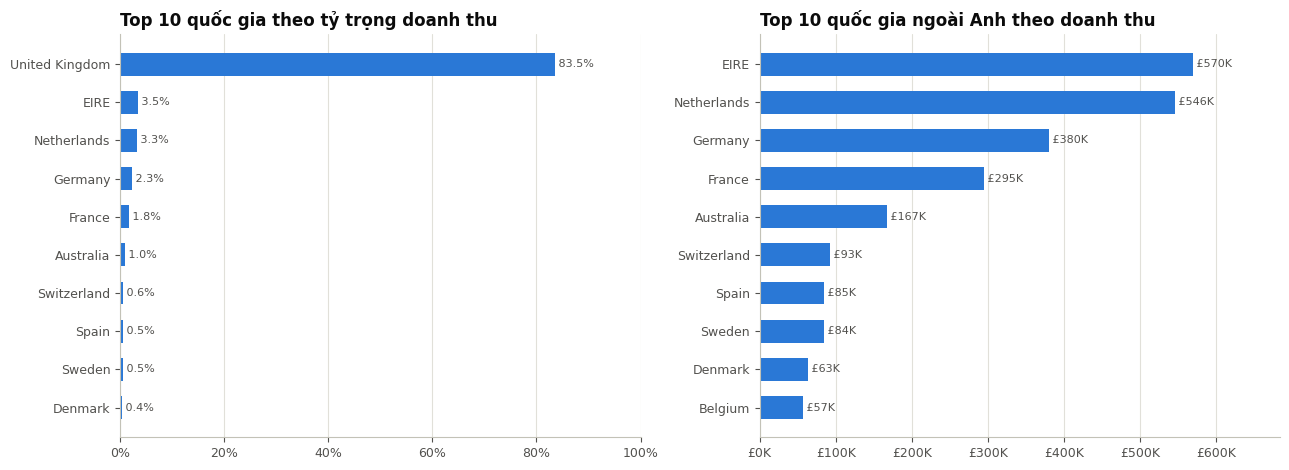

,Revenue,Customers,Invoices,RevenueShare,CustomerShare
Country,,,,,
United Kingdom,"13,760,021","5,326","33,141",83.5%,91.2%
EIRE,"569,597",3,523,3.5%,0.1%
Netherlands,"546,263",22,214,3.3%,0.4%
Germany,"380,081",107,752,2.3%,1.8%
France,"294,743",93,587,1.8%,1.6%
Australia,"166,944",15,86,1.0%,0.3%
Switzerland,"92,700",22,79,0.6%,0.4%
Spain,"85,106",38,141,0.5%,0.7%
Sweden,"84,250",19,97,0.5%,0.3%


In [19]:
country_stats = df.groupby("Country").agg(
    Revenue=("TotalPrice", "sum"),
    Customers=("CustomerID", "nunique"),
    Invoices=("Invoice", "nunique"),
).sort_values("Revenue", ascending=False)
country_stats["RevenueShare"] = country_stats["Revenue"] / country_stats["Revenue"].sum() * 100
country_stats["CustomerShare"] = country_stats["Customers"] / df["CustomerID"].nunique() * 100

top_all = country_stats.head(10).sort_values("RevenueShare")
top_non_uk = country_stats.drop("United Kingdom").head(10).sort_values("Revenue")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].barh(top_all.index, top_all["RevenueShare"], height=0.6, color=COLORS[0])
for y, v in enumerate(top_all["RevenueShare"]):
    axes[0].text(v, y, f" {v:.1f}%", va="center", fontsize=8, color=INK_2)
axes[0].set_title("Top 10 quốc gia theo tỷ trọng doanh thu")
axes[0].set_xlim(0, 100)
axes[0].xaxis.set_major_formatter(mticker.PercentFormatter())

axes[1].barh(top_non_uk.index, top_non_uk["Revenue"], height=0.6, color=COLORS[0])
for y, v in enumerate(top_non_uk["Revenue"]):
    axes[1].text(v, y, f" £{v / 1e3:,.0f}K", va="center", fontsize=8, color=INK_2)
axes[1].set_title("Top 10 quốc gia ngoài Anh theo doanh thu")
axes[1].set_xlim(0, top_non_uk["Revenue"].max() * 1.2)
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"£{x / 1e3:,.0f}K"))
for ax in axes:
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
fig.tight_layout()
save_fig(fig, "01_top10_quoc_gia.png")
plt.show()

country_stats.head(10).style.format({"Revenue": "{:,.0f}", "Customers": "{:,}", "Invoices": "{:,}",
                                     "RevenueShare": "{:.1f}%", "CustomerShare": "{:.1f}%"})

**Nhận xét:** - **Anh chiếm 83,5% doanh thu và 91,2% số khách**. Các nước còn lại đóng góp rất nhỏ.
- Ngoài Anh, EIRE (Ireland) và Hà Lan có doanh thu cao nhưng chỉ đến từ rất ít khách (3 và 22 khách), tức là vài khách sỉ lớn. Đức và Pháp có nhiều khách nhất ngoài Anh (107 và 93 khách).
- Vì dữ liệu tập trung gần như hoàn toàn ở Anh, ở notebook 03 biến `Country` sẽ được gộp thành 2 nhóm: **UK** và **Khác**.

### 3.5. Phân phối số hóa đơn của mỗi khách hàng

Mục đích: hiểu tần suất mua hàng của khách, đây cũng là cơ sở cho chỉ số Frequency trong mô hình RFM ở notebook 02. Phân phối được vẽ bằng **histogram** (C2).

count   5,839.00
mean        6.22
std        12.63
min         1.00
25%         1.00
50%         3.00
75%         7.00
max       369.00

Tỷ lệ khách chỉ mua 1 lần: 27.6%
Tỷ lệ khách mua từ 10 lần trở lên: 16.4%
Đã lưu: figures/01_phan_phoi_so_hoa_don.png


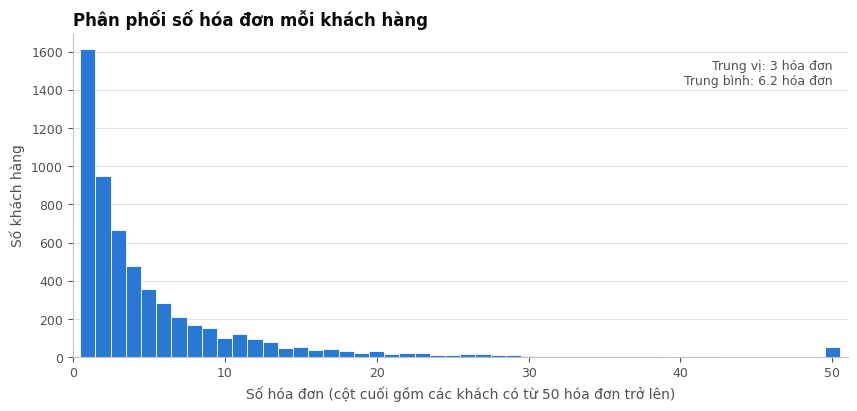

In [20]:
invoices_per_customer = df.groupby("CustomerID")["Invoice"].nunique()
print(invoices_per_customer.describe().to_string())
print(f"\nTỷ lệ khách chỉ mua 1 lần: {(invoices_per_customer == 1).mean() * 100:.1f}%")
print(f"Tỷ lệ khách mua từ 10 lần trở lên: {(invoices_per_customer >= 10).mean() * 100:.1f}%")

CAP = 50
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.hist(invoices_per_customer.clip(upper=CAP), bins=np.arange(1, CAP + 2) - 0.5,
        color=COLORS[0], edgecolor="white", linewidth=0.6)
ax.set_title("Phân phối số hóa đơn mỗi khách hàng")
ax.set_xlabel(f"Số hóa đơn (cột cuối gồm các khách có từ {CAP} hóa đơn trở lên)")
ax.set_ylabel("Số khách hàng")
ax.set_xlim(0, CAP + 1)
median_inv = invoices_per_customer.median()
ax.text(0.98, 0.92, f"Trung vị: {median_inv:.0f} hóa đơn\nTrung bình: {invoices_per_customer.mean():.1f} hóa đơn",
        transform=ax.transAxes, ha="right", va="top", fontsize=9, color=INK_2)
save_fig(fig, "01_phan_phoi_so_hoa_don.png")
plt.show()

**Nhận xét:** - Phân phối **lệch phải rất mạnh**: trung vị chỉ 3 hóa đơn, trung bình 6,2, nhưng có khách mua tới 369 lần.
- 27,6% khách chỉ mua đúng 1 lần, trong khi 16,4% khách mua từ 10 lần trở lên.
- Độ lệch lớn này là lý do ở notebook 02 cần **rời rạc hóa** Frequency (cùng Recency và Monetary) thành điểm 1 đến 5 theo đóng thùng equal-frequency (C2) trước khi phân cụm, nếu không K-Means sẽ bị chi phối bởi vài khách mua cực nhiều.

### 3.6. Phân phối giá trị đơn hàng

Giá trị đơn hàng là tổng `TotalPrice` của một hóa đơn. Phân phối này lệch phải rất mạnh nên histogram dùng **trục hoành theo thang logarit**. Đây chỉ là cách hiển thị để nhìn rõ cả đơn nhỏ lẫn đơn lớn; dữ liệu không bị biến đổi.

count   36,334.00
mean       453.40
std        914.17
min          0.38
25%        157.91
50%        301.30
75%        470.53
95%      1,196.45
99%      3,405.61
max     43,627.60


Đã lưu: figures/01_phan_phoi_gia_tri_don_hang.png


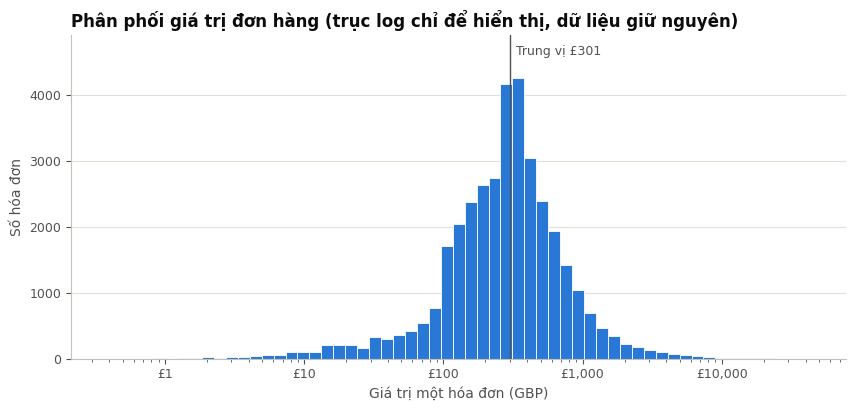

In [21]:
order_value = df.groupby("Invoice")["TotalPrice"].sum()
print(order_value.describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).to_string())

fig, ax = plt.subplots(figsize=(10, 4.2))
bins = np.logspace(np.log10(order_value.min()), np.log10(order_value.max()), 60)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"£{x:,.0f}"))
counts, _, _ = ax.hist(order_value, bins=bins, color=COLORS[0], edgecolor="white", linewidth=0.6)
ax.set_ylim(0, counts.max() * 1.15)
ax.axvline(order_value.median(), color=INK_2, linewidth=1)
ax.text(order_value.median() * 1.1, counts.max() * 1.08, f"Trung vị £{order_value.median():,.0f}",
        fontsize=9, color=INK_2)
ax.set_title("Phân phối giá trị đơn hàng (trục log chỉ để hiển thị, dữ liệu giữ nguyên)")
ax.set_xlabel("Giá trị một hóa đơn (GBP)")
ax.set_ylabel("Số hóa đơn")
save_fig(fig, "01_phan_phoi_gia_tri_don_hang.png")
plt.show()

**Nhận xét:** - Trên thang log, giá trị đơn hàng có dạng gần chuông (gần phân phối log-chuẩn), tập trung quanh **£100 đến £1.000**. Trung vị £301, trung bình £453.
- Đuôi phải dài: 5% đơn hàng trên £1.196, đơn lớn nhất £43.628. Giá trị đơn hàng trung bình cao như vậy một lần nữa cho thấy nhiều khách là khách sỉ.

#### Thống kê mô tả giá trị đơn hàng (C2)

Các độ đo trong bảng dưới đây (C2, mô tả dữ liệu):

- **Trung bình** (mean) = tổng giá trị / số hóa đơn; **trung vị** (median) là giá trị đứng giữa khi sắp xếp; **mode** là giá trị xuất hiện nhiều nhất; **midrange** = (min + max) / 2.
- **Tứ phân vị** Q1, Q3 là các giá trị chia dữ liệu đã sắp xếp tại 25% và 75%; **IQR** = Q3 - Q1.
- **Ngoại lai** theo quy tắc 1,5×IQR: giá trị lớn hơn Q3 + 1,5×IQR (hoặc nhỏ hơn Q1 - 1,5×IQR).
- **Độ lệch chuẩn** σ là căn bậc hai của phương sai σ² = (1/N) Σ (xᵢ - x̄)².

Mode được tính trên giá trị đã làm tròn đến 2 chữ số thập phân (đơn vị penny) để tránh sai số cộng số thực.

In [22]:
q1, q3 = order_value.quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
lower_fence = q1 - 1.5 * iqr
is_large = order_value > upper_fence

order_stats = pd.DataFrame({"Giá trị": [
    f"£{order_value.mean():,.2f}",
    f"£{order_value.median():,.2f}",
    f"£{order_value.round(2).mode().iloc[0]:,.2f}",
    f"£{(order_value.min() + order_value.max()) / 2:,.2f}",
    f"£{q1:,.2f}",
    f"£{q3:,.2f}",
    f"£{iqr:,.2f}",
    f"£{order_value.std():,.2f}",
    f"£{upper_fence:,.2f}",
    f"{(order_value < lower_fence).sum():,}",
    f"{is_large.sum():,} ({is_large.mean():.1%} số hóa đơn)",
    f"{order_value[is_large].sum() / order_value.sum():.1%}",
]}, index=[
    "Trung bình (mean)", "Trung vị (median)", "Mode", "Midrange", "Q1", "Q3", "IQR", "Độ lệch chuẩn",
    "Ngưỡng trên Q3 + 1,5×IQR", "Số hóa đơn dưới Q1 - 1,5×IQR",
    "Số hóa đơn vượt Q3 + 1,5×IQR", "Tỷ trọng doanh thu của các hóa đơn vượt ngưỡng",
])
display(order_stats)

large_orders = df[df["Invoice"].isin(order_value[is_large].index)]
print(f"Hóa đơn vượt ngưỡng: số sản phẩm khác nhau TB = {large_orders.groupby('Invoice')['StockCode'].nunique().mean():.1f}, "
      f"tổng số lượng TB = {large_orders.groupby('Invoice')['Quantity'].sum().mean():,.0f}")
normal_orders = df[df["Invoice"].isin(order_value[~is_large].index)]
print(f"Hóa đơn còn lại:   số sản phẩm khác nhau TB = {normal_orders.groupby('Invoice')['StockCode'].nunique().mean():.1f}, "
      f"tổng số lượng TB = {normal_orders.groupby('Invoice')['Quantity'].sum().mean():,.0f}")

,Giá trị
Trung bình (mean),£453.40
Trung vị (median),£301.30
Mode,£15.00
Midrange,"£21,813.99"
Q1,£157.91
Q3,£470.53
IQR,£312.62
Độ lệch chuẩn,£914.17
"Ngưỡng trên Q3 + 1,5×IQR",£939.45
"Số hóa đơn dưới Q1 - 1,5×IQR",0


Hóa đơn vượt ngưỡng: số sản phẩm khác nhau TB = 40.9, tổng số lượng TB = 1,411
Hóa đơn còn lại:   số sản phẩm khác nhau TB = 19.2, tổng số lượng TB = 182


**Nhận xét:** - **Trung bình (£453) lớn hơn hẳn trung vị (£301)** và độ lệch chuẩn (£914) gấp đôi trung bình: phân phối lệch phải mạnh. Midrange (£21.814) gần như chỉ phản ánh đơn lớn nhất (£43.628), hoàn toàn không đại diện cho một hóa đơn điển hình. Mode (£15) là một mức tiền lặp lại nhiều lần, nhưng với dữ liệu gần như liên tục thì mode không nói lên nhiều.
- Theo quy tắc 1,5×IQR (IQR = £313, ngưỡng trên £939), có **2.830 hóa đơn (7,8%) là ngoại lai phía trên**, chiếm tới **38,1% doanh thu**. Không có ngoại lai phía dưới, vì Q1 - 1,5×IQR là số âm.
- **Các đơn lớn được giữ lại, không coi là nhiễu.** Trung bình mỗi hóa đơn vượt ngưỡng có 40,9 sản phẩm khác nhau và 1.411 đơn vị hàng, so với 19,2 sản phẩm và 182 đơn vị ở các hóa đơn còn lại: đây là các đơn nhập hàng sỉ thật của khách bán lại. Các lỗi ghi nhận thật sự (đơn hủy, số lượng hoặc giá ≤ 0, mã không phải sản phẩm) đã được loại ở các bước làm sạch. Ngoại lai theo 1,5×IQR chỉ là dấu hiệu cần kiểm tra; nếu loại các đơn này, dữ liệu sẽ mất gần 40% doanh thu và mất đúng hành vi của nhóm khách giá trị nhất.
- **Trung vị đại diện tốt hơn trung bình** cho "một hóa đơn điển hình": trung bình bị kéo lên bởi số ít đơn rất lớn, còn trung vị chỉ phụ thuộc vào giá trị đứng giữa nên không bị ngoại lai ảnh hưởng. Vì vậy các notebook sau ưu tiên dùng trung vị khi mô tả các biến lệch.

## 4. Tạo nhãn rời bỏ (churn)

### 4.1. Định nghĩa

Đây là bước **chọn lựa dữ liệu** (C1, quy trình KDD) và **xác định thuộc tính lớp** cho bài toán phân lớp (C4): chọn tập khách hàng, khoảng thời gian dùng để tính thuộc tính và khoảng thời gian dùng để gán nhãn.

Dữ liệu được chia theo thời gian thành hai giai đoạn:

| Giai đoạn | Thời gian | Vai trò |
|---|---|---|
| Quan sát | 01/12/2009 đến **hết 09/09/2011** | Tính mọi đặc trưng của khách hàng |
| Dự đoán | **10/09/2011 đến 09/12/2011** (3 tháng cuối) | Chỉ dùng để tạo nhãn churn |

- **Ngày tham chiếu** (dùng tính Recency ở các notebook sau): **10/09/2011**.
- **Nhãn:** `churn = 1` nếu khách **không có giao dịch nào** trong giai đoạn dự đoán; ngược lại `churn = 0`.
- **Tập khách hàng nghiên cứu:** khách có ít nhất một giao dịch trong giai đoạn quan sát **và** có mua hàng trong 12 tháng cuối của giai đoạn quan sát (từ 10/09/2010 trở đi).

**Lý do giới hạn tập khách hàng:** khách đã ngưng mua hơn một năm (lần mua cuối trước 10/09/2010) coi như đã mất. Gần như chắc chắn họ cũng không quay lại trong 3 tháng tiếp theo, nên việc "dự đoán" họ không có giá trị kinh doanh, đồng thời làm mô hình trông tốt hơn thực tế vì những trường hợp này quá dễ đoán. Bảng so sánh bên dưới cho thấy ảnh hưởng của lựa chọn này.

 Giai đoạn dự đoán **chỉ được dùng để tạo nhãn**, không dùng để tính bất kỳ đặc trưng nào (tránh rò rỉ dữ liệu, *data leakage*).

In [23]:
obs = df[df["InvoiceDate"] < REF_DATE]
pred = df[(df["InvoiceDate"] >= REF_DATE) & (df["InvoiceDate"] < PRED_END)]
print(f"Giai đoạn quan sát: {obs['InvoiceDate'].min():%d/%m/%Y} đến {obs['InvoiceDate'].max():%d/%m/%Y}, "
      f"{len(obs):,} dòng, {obs['CustomerID'].nunique():,} khách")
print(f"Giai đoạn dự đoán:  {pred['InvoiceDate'].min():%d/%m/%Y} đến {pred['InvoiceDate'].max():%d/%m/%Y}, "
      f"{len(pred):,} dòng, {pred['CustomerID'].nunique():,} khách")

Giai đoạn quan sát: 01/12/2009 đến 09/09/2011, 613,315 dòng, 5,248 khách
Giai đoạn dự đoán:  11/09/2011 đến 09/12/2011, 157,373 dòng, 2,876 khách


In [24]:
obs_customers = obs.groupby("CustomerID")["InvoiceDate"].max().rename("LastPurchase").to_frame()

buyers_in_pred = set(pred["CustomerID"])
obs_customers["churn"] = (~obs_customers.index.isin(buyers_in_pred)).astype(int)

is_active = obs_customers["LastPurchase"] >= ACTIVE_START

comparison = pd.DataFrame({
    "Tập khách hàng": [
        "Tất cả khách trong giai đoạn quan sát",
        "Khách đã ngưng mua > 12 tháng (bị loại)",
        "Khách có mua từ 10/09/2010 (được chọn)",
    ],
    "Số khách": [len(obs_customers), (~is_active).sum(), is_active.sum()],
    "Tỷ lệ churn (%)": [
        obs_customers["churn"].mean() * 100,
        obs_customers.loc[~is_active, "churn"].mean() * 100,
        obs_customers.loc[is_active, "churn"].mean() * 100,
    ],
})
comparison.style.format({"Số khách": "{:,}", "Tỷ lệ churn (%)": "{:.1f}"}).hide(axis="index")

Tập khách hàng,Số khách,Tỷ lệ churn (%)
Tất cả khách trong giai đoạn quan sát,"5,248",56.5
Khách đã ngưng mua > 12 tháng (bị loại),949,89.3
Khách có mua từ 10/09/2010 (được chọn),"4,299",49.2


In [25]:
customers = obs_customers[is_active].reset_index()[["CustomerID", "churn"]]

new_customers_in_pred = len(buyers_in_pred - set(obs_customers.index))
print(f"Số khách trong tập nghiên cứu: {len(customers):,}")
print(f"Khách mới xuất hiện lần đầu trong giai đoạn dự đoán (không thuộc tập nghiên cứu): {new_customers_in_pred:,}")
print("\nPhân bố nhãn churn:")
churn_counts = customers["churn"].value_counts().sort_index()
print(pd.DataFrame({"Số khách": churn_counts, "Tỷ lệ (%)": churn_counts / len(customers) * 100}).round(1).to_string())

Số khách trong tập nghiên cứu: 4,299
Khách mới xuất hiện lần đầu trong giai đoạn dự đoán (không thuộc tập nghiên cứu): 591

Phân bố nhãn churn:
       Số khách  Tỷ lệ (%)
churn                     
0          2183      50.80
1          2116      49.20


Đã lưu: figures/01_ty_le_churn.png


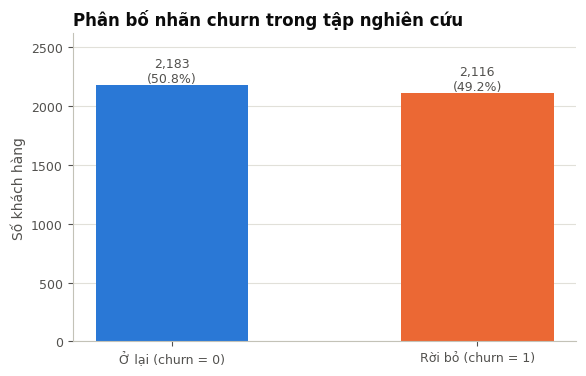

In [26]:
labels = ["Ở lại (churn = 0)", "Rời bỏ (churn = 1)"]
fig, ax = plt.subplots(figsize=(6.5, 4))
bars = ax.bar(labels, churn_counts.values, width=0.5, color=[COLORS[0], COLORS[1]])
for bar, n in zip(bars, churn_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n, f"{n:,}\n({n / len(customers) * 100:.1f}%)",
            ha="center", va="bottom", fontsize=9, color=INK_2)
ax.set_ylim(0, churn_counts.max() * 1.2)
ax.set_ylabel("Số khách hàng")
ax.set_title("Phân bố nhãn churn trong tập nghiên cứu")
save_fig(fig, "01_ty_le_churn.png")
plt.show()

**Nhận xét:** - Tập nghiên cứu gồm **4.299 khách**, trong đó **49,2% rời bỏ** (2.116 khách) và 50,8% ở lại. Hai lớp **gần cân bằng**, nên ở notebook 03 có thể dùng **độ chính xác (accuracy)** làm tiêu chí đánh giá mô hình phân lớp (C4): một mô hình chỉ đoán toàn bộ là lớp đông hơn cũng chỉ đạt khoảng 51%.
- 949 khách bị loại (ngưng mua hơn 12 tháng) có tỷ lệ churn tới **89,3%**. Nếu giữ họ lại, tỷ lệ churn chung tăng lên 56,5% và mô hình sẽ được "cho điểm" nhờ những ca quá dễ đoán. Kết quả này ủng hộ lựa chọn giới hạn tập khách hàng.
- 591 khách mua lần đầu trong giai đoạn dự đoán không có lịch sử để tính đặc trưng, nên không thuộc tập nghiên cứu.

## 5. Xuất dữ liệu

- `transactions_clean.csv`: **toàn bộ** giao dịch đã làm sạch (cả hai giai đoạn). Các notebook sau tự lọc giai đoạn quan sát khi tính đặc trưng.
- `customers.csv`: danh sách khách hàng trong tập nghiên cứu và nhãn churn.

In [27]:
df.to_csv(PROCESSED_DIR / "transactions_clean.csv", index=False)
customers.to_csv(PROCESSED_DIR / "customers.csv", index=False)
print(f"transactions_clean.csv: {df.shape}")
print(f"customers.csv: {customers.shape}")

transactions_clean.csv: (770688, 9)
customers.csv: (4299, 2)


## 6. Tóm tắt

| Nội dung | Kết quả |
|---|---|
| Dữ liệu gốc | 1.067.371 dòng, 01/12/2009 đến 09/12/2011 |
| Sau làm sạch | 770.688 dòng (72,2%), 36.334 hóa đơn, 5.839 khách, 4.611 sản phẩm, 41 quốc gia |
| Tổng doanh thu sau làm sạch | khoảng £16,5 triệu |
| Đặc điểm nổi bật | Doanh thu mùa vụ (đỉnh tháng 11); Anh chiếm 83,5% doanh thu; số hóa đơn mỗi khách và giá trị đơn hàng lệch phải mạnh |
| Tập khách nghiên cứu | 4.299 khách có mua trong 12 tháng trước 10/09/2011 |
| Tỷ lệ churn | 49,2% (gần cân bằng) |

Notebook 02 sẽ dùng `transactions_clean.csv` và `customers.csv` để tính RFM và phân cụm khách hàng.